# Does inserting a co-operating partner motif raise P(bound)?

For each focal motif, take real unbound genomic windows that contain it, and at a range of distances **replace that
many bases with the consensus of a transcription factor it is documented to co-operate with**. Record

$$\Delta P = P(\text{bound, partner inserted}) - P(\text{bound, same background, nothing inserted})$$

in three backgrounds: the real window, the window with everything outside the motif's own tokens shuffled, and the
window with everything outside the motif's own tokens redrawn at random.

The motif's **own** consensus is inserted the same way, as a scale reference. That is not a control — it answers
"how much can anything at this distance move this readout at all", without which a partner number of +0.03 cannot be
called large or small. `INCLUDE_SELF = False` switches it off.

## Choosing the pairs

The ten motifs are the highest-AUC **human** profiles that have a partner of the right *kind*: a separate site at a
distance. Three classes of well-known partnership are deliberately excluded, because a distance sweep cannot
represent them:

| excluded | why |
|---|---|
| MAFF / MAFG / MAFK + NFE2L2, BACH1 | small MAF binds the MARE/ARE as an **obligate heterodimer** — the two half-sites are one composite element, not two sites apart |
| USF1 + USF2, JUN + FOS | likewise dimers sharing one site |
| CTCF + CTCFL | the same motif; a family confound, not a partnership |
| ZNF143 + CTCF | contested — the original claim may reflect **antibody cross-reactivity with CTCF**; ZNF143's THAP11/HCFC1 partners bind **overlapping** sites |
| ZNF436, ZNF460, ZNF652, ZNF707, ZNF57 | KRAB zinc fingers with no documented partner |

Three of the pairs that remain carry a **specific, testable prediction** rather than mere co-occurrence:

* **FOXA1/FOXA3 + HNF4A** — co-bound sites in HepG2 are enriched at **15–60 bp** spacing, with no composite motif.
* **NRF1 or NFYA + SP1** — upstream of Sp1 strengthens initiation, downstream represses, so the **two sides should
  differ**. Section 3 reports left and right separately.
* **STAT1 + IRF1** — GAS and ISRE about **12 bp** apart at gp91phox.

Replacement, not insertion, so the window stays 600 bp and the 6-mer tokenisation does not shift; the focal motif's
own tokens are byte-identical in every row of a pair, so ΔP at layer 0 must be exactly 0 (asserted in Section 3).


In [1]:
!pip install -q pymemesuite scipy pandas matplotlib


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


## 1.1 Settings and the literature pair list


In [3]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, time
import numpy as np, pandas as pd

C = json.load(open(f"{WORK_DIR}/config.json"))
OUT = f"{WORK_DIR}/partner_insert"
os.makedirs(OUT, exist_ok=True)
TOK, MOFF, WLEN = C["tok"], C["motif_offset"], C["window_len"]
LP = C["primary_layer"]

N_MOTIF, N_WIN = 10, 10
DISTS = [6, 12, 18, 24, 36, 48, 72, 96, 150]
SIDES = ["L", "R"]
BACKGROUNDS = ["real", "shuffled", "random"]
INCLUDE_SELF = True
N_RAND = 5                 # random ACGT words, the same length as the partner's consensus, per placement
MIN_SITES, SEED = 400, 0

# focal, partner, what the literature says. One partner per focal: the first entry that is available.
COOP_PAIRS = [
    # FOX sits at the synergy end of the cooperativity spectrum with AP-1, not with HNF4A: AP-1, not CEBPB or
    # HNF4A, is FOXA1's top partner in HepG2 (Mol Cell 2024). The HNF4A pairing is kept only as a fallback.
    ("FOXA1", "JUND",   "FOXA1-AP-1 synergy; AP-1 is the top partner in HepG2, not CEBPB (Mol Cell 2024)"),
    ("FOXA1", "JUN",    "as JUND"),
    ("FOXA1", "FOSL2",  "as JUND"),
    ("FOXA2", "JUND",   "as FOXA1"),
    ("FOXA3", "JUND",   "as FOXA1"),
    ("FOXA3", "JUN",    "as JUND"),
    ("FOXA3", "FOSL2",  "as JUND"),
    ("FOXA1", "HNF4A",  "fallback: co-bound at 15-60 bp spacing in HepG2 (bioRxiv 2026)"),
    ("FOXA2", "HNF4A",  "fallback, as FOXA1"),
    ("FOXA3", "HNF4A",  "fallback, as FOXA1"),
    ("HNF4A", "FOXA1",  "reciprocal of FOXA1 + HNF4A"),
    ("HNF4A", "CEBPB",  "liver core circuit"),
    ("SP1",   "NFYA",   "GC-box sits ~10 bp 5' and 3' of a CCAAT box (NF-Y / SP review)"),
    ("SP2",   "NFYA",   "as SP1"),
    ("SP4",   "NFYA",   "as SP1"),
    ("SP1",   "NRF1",   "NRF1 upstream of Sp1 strengthens initiation, downstream represses (Nature 2024)"),
    ("SP2",   "NRF1",   "as SP1"),
    ("SP4",   "NRF1",   "as SP1"),
    ("NRF1",  "SP1",    "reciprocal; both prefer positions upstream of the TSS"),
    ("NFYA",  "SP1",    "reciprocal of SP1 + NFYA"),
    ("STAT1", "IRF1",   "GAS and ISRE ~12 bp apart at the gp91phox promoter (JBC)"),
    ("STAT2", "IRF1",   "as STAT1"),
    ("ELF1",  "SP1",    "ETS beside a GC-box at housekeeping promoters; position-dependent (Nature 2024)"),
    ("ETV1",  "SP1",    "as ELF1"),
    ("GABPA", "SP1",    "as ELF1"),
    ("ELF1",  "NFYA",   "ETS beside CCAAT"),
    ("GABPA", "NFYA",   "as ELF1"),
    ("ETV1",  "NFYA",   "as ELF1"),
    ("YY1",   "SP1",    "YY1 with a GC-box at CpG-island promoters"),
    ("ELK1",  "SRF",    "ternary complex at the serum response element"),
    ("GATA1", "TAL1",   "GATA-E-box composite, erythroid, preferred spacing ~8-10 bp"),
    ("GATA2", "TAL1",   "as GATA1"),
    ("GATA1", "KLF1",   "erythroid co-binding"),
    ("CEBPB", "ATF4",   "C/EBP-ATF element at amino-acid-response genes"),
    ("RUNX1", "ETS1",   "RUNX-ETS composite"),
]
WHY_NOT = {
    "MAFK": "small MAF binds the ARE as an obligate heterodimer with NFE2L2/BACH1 - one composite element",
    "MAFF": "as MAFK", "MAFG": "as MAFK", "NFE2": "as MAFK",
    "CTCFL": "binds the same motif as CTCF - a family confound, not a partnership",
    "CTCF": "the ZNF143 partnership is contested (antibody cross-reactivity); cohesin is not a motif",
    "ZNF143": "THAP11/HCFC1 bind overlapping sites; the CTCF link is contested",
    "USF1": "the documented partner USF2 is an obligate dimer on the same E-box",
    "USF2": "as USF1",
}
json.dump({"n_motif": N_MOTIF, "n_win": N_WIN, "dists": DISTS, "sides": SIDES, "backgrounds": BACKGROUNDS,
           "include_self": INCLUDE_SELF, "n_rand": N_RAND, "min_sites": MIN_SITES, "seed": SEED, "layer": LP},
          open(f"{OUT}/config.json", "w"), indent=1)
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 250)


## 1.2 Which motifs make the list


In [4]:
SRCS = [("fcav_pgc_hk", "fcav_pgc_hk_lr"), ("fcav_pgc_hk_r0", "fcav_pgc_hk_lr_r0"),
        ("fcav_pgc_hk_r20", "fcav_pgc_hk_lr_r20")]
FIT_OF, SITE_OF = {}, {}
for src, fit in SRCS:
    S, F = f"{WORK_DIR}/{src}", f"{WORK_DIR}/{fit}"
    if not os.path.exists(f"{S}/mpra_windows.json"):
        continue
    for m, st in json.load(open(f"{S}/mpra_windows.json"))["status"].items():
        if st == "built" and m not in FIT_OF and os.path.exists(f"{F}/fits/{m}.npz"):
            FIT_OF[m], SITE_OF[m] = f"{F}/fits/{m}.npz", f"{S}/sites/{m}.json"

rows = []
for m in sorted(FIT_OF):
    z = np.load(FIT_OF[m])
    J = json.load(open(SITE_OF[m]))
    y = np.array([r["cls"] for r in J["records"]])
    rows.append({"motif": m, "AUC": float(z["auc"][LP]), "bound": int(y.sum()), "unbound": int((y == 0).sum()),
                 "width": J["width"], "K0": J["K0"], "K1": J["K1"]})
AV = pd.DataFrame(rows).set_index("motif")

from pymemesuite.common import MotifFile
with MotifFile(C["meme_path"]) as _mf:
    _all = list(_mf)
MOTIF = {}
for _m in _all:
    MOTIF.setdefault(_m.name.decode(), _m)
BY_SYM = {}
for _n in MOTIF:
    BY_SYM.setdefault(_n.upper(), []).append(_n)


def resolve(sym):
    # JASPAR writes a human profile in caps and a mouse one in title case; the ChIP data is human
    c = BY_SYM.get(sym.upper(), [])
    return next((x for x in c if x.isupper()), c[0] if c else None)


def consensus(name):
    f = np.asarray(MOTIF[name].frequencies, float)
    return "".join("ACGT"[i] for i in (f / f.sum(1, keepdims=True)).argmax(1))


PARTNER = {}
for f_, p_, note in COOP_PAIRS:
    r = resolve(p_)
    if r is not None and f_ not in PARTNER:
        PARTNER[f_] = (r, p_, note)

elig = []
for m in AV.index:
    bad = (None if m.isupper() else "not a human profile (title case = mouse)")
    if bad is None and min(AV.at[m, "bound"], AV.at[m, "unbound"]) < MIN_SITES:
        bad = f"fewer than {MIN_SITES} sites in a class"
    if bad is None and m not in PARTNER:
        bad = WHY_NOT.get(m, "no documented partner of the separate-site kind")
    elig.append({"motif": m, "AUC": AV.at[m, "AUC"], "partner": PARTNER.get(m, ("", "", ""))[0],
                 "why not": bad or ""})
EL = pd.DataFrame(elig).sort_values("AUC", ascending=False)
MOTIFS = EL[EL["why not"] == ""]["motif"].tolist()[:N_MOTIF]

print(f"{len(AV)} motifs with a direction; {(EL['why not'] == '').sum()} are human, big enough and have a "
      f"separate-site partner")
print(f"\n=== the top {min(25, len(EL))} by AUC at L{LP}, and why each is in or out")
print(EL.head(25).to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\n=== the {len(MOTIFS)} chosen")
for m in MOTIFS:
    p, sym, note = PARTNER[m]
    print(f"  {m:8s} AUC {AV.at[m, 'AUC']:.3f}  +  {p:8s}"
          + ("" if p == sym else f" (asked for {sym})") + f"   {note}")
    print(f"           {m} = {consensus(m)} ({len(consensus(m))} bp)   {p} = {consensus(p)} "
          f"({len(consensus(p))} bp)")
assert len(MOTIFS) >= 2, "too few eligible motifs"


110 motifs with a direction; 9 are human, big enough and have a separate-site partner

=== the top 25 by AUC at L15, and why each is in or out
 motif   AUC partner                                                                                      why not
ZNF436 0.947                                                      no documented partner of the separate-site kind
  MAFK 0.933         small MAF binds the ARE as an obligate heterodimer with NFE2L2/BACH1 - one composite element
ZNF707 0.924                                                      no documented partner of the separate-site kind
ZNF143 0.917                                      THAP11/HCFC1 bind overlapping sites; the CTCF link is contested
ZNF460 0.911                                                      no documented partner of the separate-site kind
 Stat2 0.907                                                             not a human profile (title case = mouse)
  Mafg 0.904                                               

## 1.3 Build the sequences

Each row carries its full 600 bp sequence, so Section 2 reconstructs nothing.


In [5]:
def make_bg(win, lo, hi, kind):
    # keep [lo, hi) - the focal motif's own tokens - and rebuild everything else
    if kind == "real":
        return win
    out = list(win[:lo]) + list(win[hi:])
    out = list(rng.permutation(out)) if kind == "shuffled" else list(rng.choice(list("ACGT"), len(out)))
    return "".join(out[:lo]) + win[lo:hi] + "".join(out[lo:])


def place(lo, hi, side, d, L):
    pos = lo - d - L if side == "L" else hi + d
    ok = 0 <= pos and pos + L <= WLEN and (pos + L <= lo or pos >= hi)
    return pos if ok else None


V = []
t0 = time.time()
for m in MOTIFS:
    lo, hi = int(AV.at[m, "K0"]) * TOK, int(AV.at[m, "K1"]) * TOK
    pcon = consensus(PARTNER[m][0])
    words = [(PARTNER[m][0], consensus(PARTNER[m][0]), "partner", 0)]
    if INCLUDE_SELF:
        words.append((m, consensus(m), "self", 0))
    R = json.load(open(SITE_OF[m]))["records"]
    cls = np.array([r["cls"] for r in R])
    for wi in [int(i) for i in rng.permutation(np.flatnonzero(cls == 0))[:N_WIN]]:
        for bg in BACKGROUNDS:
            base = make_bg(R[wi]["window"], lo, hi, bg)
            assert len(base) == WLEN and base[lo:hi] == R[wi]["window"][lo:hi]
            V.append({"motif": m, "wi": wi, "bg": bg, "ins": "", "role": "none", "draw": 0,
                      "side": "", "d": -1, "pos": -1, "seq": base})
            for side in SIDES:
                for d in DISTS:
                    # the partner, and the motif itself as a scale reference
                    for name, con, role, _ in words:
                        pos = place(lo, hi, side, d, len(con))
                        if pos is None:
                            continue
                        seq = base[:pos] + con + base[pos + len(con):]
                        assert len(seq) == WLEN and seq[lo:hi] == base[lo:hi]
                        V.append({"motif": m, "wi": wi, "bg": bg, "ins": name, "role": role, "draw": 0,
                                  "side": side, "d": d, "pos": pos, "seq": seq})
                    # N_RAND random ACGT words of exactly the partner's length
                    pos = place(lo, hi, side, d, len(pcon))
                    if pos is None:
                        continue
                    for k in range(N_RAND):
                        word = "".join(rng.choice(list("ACGT"), len(pcon)))
                        seq = base[:pos] + word + base[pos + len(word):]
                        assert len(seq) == WLEN and seq[lo:hi] == base[lo:hi]
                        V.append({"motif": m, "wi": wi, "bg": bg, "ins": "random", "role": "randseq", "draw": k,
                                  "side": side, "d": d, "pos": pos, "seq": seq})
V = pd.DataFrame(V)
V.insert(0, "vid", np.arange(len(V)))
V.to_csv(f"{OUT}/variants.csv", index=False)
json.dump({m: {"K0": int(AV.at[m, "K0"]), "K1": int(AV.at[m, "K1"]), "AUC": float(AV.at[m, "AUC"]),
               "partner": PARTNER[m][0], "note": PARTNER[m][2], "consensus": consensus(m),
               "partner_consensus": consensus(PARTNER[m][0])} for m in MOTIFS},
          open(f"{OUT}/motifs.json", "w"), indent=1)
print(f"{len(V):,} sequences [{time.time() - t0:.0f}s];  {len(V) / 48:.0f} batches of 48")
print(V[V.d > 0].groupby(["motif", "role"]).size().unstack(fill_value=0).to_string())


34,290 sequences [4s];  714 batches of 48
role   partner  randseq  self
motif                        
ELF1       540     2700   540
ETV1       540     2700   540
FOXA1      540     2700   540
FOXA3      540     2700   540
GABPA      540     2700   540
SP1        540     2700   540
SP2        540     2700   540
SP4        540     2700   540
STAT1      540     2700   540


## 1.4 End of Section 1 — switch to a GPU runtime


In [6]:
from google.colab import runtime
runtime.unassign()


---
# Section 2 — project onto each motif's frozen direction *(GPU runtime)*

Each row carries its own full 600 bp sequence, so nothing is reconstructed here. The focal motif's tokens
`[K0, K1)` are averaged at every hidden state, standardised with that motif's stored `mu`/`sd` and pushed through its
stored `w_all`. Nothing is refitted.


In [1]:
!pip install -q -U "transformers==4.57.6" "tokenizers==0.22.0" "huggingface_hub==0.34.0" "safetensors==0.4.5"


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.34.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.34.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.34.0 which is incompatible.
diffusers 0.41.0 requires safetensors>=0.8.0, but you have safetensors 0.4.5 which is incompatible.


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [3]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, time, gc, hashlib
import numpy as np, pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

C = json.load(open(f"{WORK_DIR}/config.json"))
OUT = f"{WORK_DIR}/partner_insert"
os.makedirs(f"{OUT}/logits", exist_ok=True)
V = pd.read_csv(f"{OUT}/variants.csv", keep_default_na=False)
MJ = json.load(open(f"{OUT}/motifs.json"))
WLEN = C["window_len"]
SRCS = ["fcav_pgc_hk_lr", "fcav_pgc_hk_lr_r0", "fcav_pgc_hk_lr_r20"]
FITP = {m: next(f"{WORK_DIR}/{s}/fits/{m}.npz" for s in SRCS
                if os.path.exists(f"{WORK_DIR}/{s}/fits/{m}.npz")) for m in V.motif.unique()}

DEV = torch.device("cuda")
TOKZ = AutoTokenizer.from_pretrained(C["model_name"], trust_remote_code=True)
MODEL = AutoModelForMaskedLM.from_pretrained(C["model_name"], trust_remote_code=True).to(DEV).eval()
NL = MODEL.config.num_hidden_layers
LAYERS = list(range(NL + 1))
_ids = TOKZ("A" * WLEN)["input_ids"]
LEAD = int(_ids[0] == TOKZ.cls_token_id)
TRAIL = int(TOKZ.eos_token_id is not None and _ids[-1] == TOKZ.eos_token_id)
assert len(_ids) - LEAD - TRAIL == WLEN // C["tok"]
print(f"{C['model_name']}: layers 0-{NL}; {len(V):,} sequences over {V.motif.nunique()} motifs")


@torch.no_grad()
def logit_of(seqs, k0, k1, w, b, mu, sd, batch=48):
    out = np.zeros((len(seqs), len(LAYERS)), np.float32)
    for i in range(0, len(seqs), batch):
        ids = TOKZ(seqs[i:i + batch], return_tensors="pt")["input_ids"].to(DEV)
        assert ids.shape[1] == LEAD + WLEN // C["tok"] + TRAIL
        S = torch.stack(MODEL(input_ids=ids, output_hidden_states=True).hidden_states, 1)
        E = S[:, :, LEAD + k0:LEAD + k1].mean(2).float()
        out[i:i + E.shape[0]] = (torch.einsum("blh,lh->bl", (E - mu) / sd, w) + b).cpu().numpy()
        del S, E
    return out


t_all = time.time()
for k, (m, g) in enumerate(V.groupby("motif")):
    p = f"{OUT}/logits/{m}.npz"
    sig = hashlib.sha1(g[["vid", "seq"]].to_csv(index=False).encode()).hexdigest()
    if os.path.exists(p):
        z = np.load(p)
        if "sig" in z and str(z["sig"]) == sig:
            continue
        print(f"[{k + 1}] {m}: logits do not match variants.csv - recomputing", flush=True)
    t0 = time.time()
    F = np.load(FITP[m])
    mu = torch.tensor(F["mu"], dtype=torch.float32, device=DEV)
    sd = torch.tensor(F["sd"], dtype=torch.float32, device=DEV)
    w = torch.tensor(F["w_all"][:, :-1], dtype=torch.float32, device=DEV)
    b = torch.tensor(F["w_all"][:, -1], dtype=torch.float32, device=DEV)
    lg = logit_of(g["seq"].tolist(), MJ[m]["K0"], MJ[m]["K1"], w, b, mu, sd)
    np.savez(p, vid=g["vid"].values, logit=lg, layers=np.array(LAYERS), sig=np.array(sig))
    q = 1 / (1 + np.exp(-lg[(g["d"] == -1).values, C["primary_layer"]]))
    bgs = g.loc[g["d"] == -1, "bg"].values
    print(f"[{k + 1}] {m:8s} + {MJ[m]['partner']:8s} {len(g):6,d} seqs  baseline P: "
          + "  ".join(f"{b_} {q[bgs == b_].mean():.3f}" for b_ in sorted(set(bgs)))
          + f"  [{time.time() - t0:.0f}s, {(time.time() - t_all) / 60:.1f} min]", flush=True)
    del lg; gc.collect(); torch.cuda.empty_cache()
print("done")


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/129 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/101 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

esm_config.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/InstaDeepAI/nucleotide-transformer-v2-500m-multi-species:
- esm_config.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_esm.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/InstaDeepAI/nucleotide-transformer-v2-500m-multi-species:
- modeling_esm.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/1.99G [00:00<?, ?B/s]

InstaDeepAI/nucleotide-transformer-v2-500m-multi-species: layers 0-29; 34,290 sequences over 9 motifs
[1] ELF1: logits do not match variants.csv - recomputing
[1] ELF1     + SP1       3,810 seqs  baseline P: random 0.450  real 0.382  shuffled 0.411  [28s, 0.5 min]
[2] ETV1: logits do not match variants.csv - recomputing
[2] ETV1     + SP1       3,810 seqs  baseline P: random 0.369  real 0.398  shuffled 0.512  [27s, 1.0 min]
[3] FOXA1: logits do not match variants.csv - recomputing
[3] FOXA1    + JUND      3,810 seqs  baseline P: random 0.357  real 0.388  shuffled 0.295  [28s, 1.5 min]
[4] FOXA3: logits do not match variants.csv - recomputing
[4] FOXA3    + JUND      3,810 seqs  baseline P: random 0.292  real 0.243  shuffled 0.293  [27s, 1.9 min]
[5] GABPA: logits do not match variants.csv - recomputing
[5] GABPA    + SP1       3,810 seqs  baseline P: random 0.278  real 0.219  shuffled 0.336  [27s, 2.4 min]
[6] SP1: logits do not match variants.csv - recomputing
[6] SP1      + NFYA     

## 2.1 End of Section 2 — switch back to CPU


In [4]:
from google.colab import runtime
runtime.unassign()


---
# Section 3 — box plots and p-values *(CPU runtime)*

Each inserted row is paired with the **no-insert row of the same window in the same background**, so the background
cancels and only the inserted consensus differs. One value per window (the two sides averaged) is the unit for the
Wilcoxon; with `N_WIN = 10` the smallest attainable two-sided p is 2/2¹⁰ ≈ 0.002, so a 0.002 means "all ten windows
moved the same way" and cannot go lower.


In [1]:
!pip install -q scipy pandas matplotlib


In [2]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [3]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

C = json.load(open(f"{WORK_DIR}/config.json"))
OUT = f"{WORK_DIR}/partner_insert"
SC = json.load(open(f"{OUT}/config.json"))
MJ = json.load(open(f"{OUT}/motifs.json"))
V = pd.read_csv(f"{OUT}/variants.csv", keep_default_na=False).drop(columns=["seq"])
LP = SC["layer"]
pd.set_option("display.width", 250)
INK = "#52514e"
BG_C = {"real": "#2a78d6", "shuffled": "#eb6834", "random": "#2fa37a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})

MOTIFS = [m for m in MJ if os.path.exists(f"{OUT}/logits/{m}.npz")]
LAYERS = list(np.load(f"{OUT}/logits/{MOTIFS[0]}.npz")["layers"])
LG = np.full((len(V), len(LAYERS)), np.nan, np.float32)
for m in MOTIFS:
    z = np.load(f"{OUT}/logits/{m}.npz")
    LG[z["vid"]] = z["logit"]
V = V[V.motif.isin(MOTIFS)].copy()
bad = V.loc[~np.isfinite(LG[V["vid"].values]).all(1)]
assert not len(bad), f"no logit for {sorted(bad.motif.unique())} - re-run Section 2"
P = 1 / (1 + np.exp(-LG))

REF = V[V.d == -1].set_index(["motif", "wi", "bg"])["vid"]
S = V[V.d > 0].copy()
key = list(zip(S.motif, S.wi, S.bg))
D = P[S["vid"].values] - P[REF.loc[key].values]
S["dP"] = D[:, LP]
S["P_ref"] = P[REF.loc[key].values, LP]
assert np.abs(D[:, 0]).max() < 1e-6, f"layer 0 moved {np.abs(D[:, 0]).max():.2e} - an insert hit the motif tokens"
print(f"{len(S):,} insertions over {len(MOTIFS)} motifs; layer-0 |ΔP| max {np.abs(D[:, 0]).max():.1e} (must be 0)")
print(f"\nbaseline P(bound) at L{LP}, nothing inserted:")
print(V[V.d == -1].assign(P=P[V.loc[V.d == -1, "vid"].values, LP]).pivot_table(
    index="motif", columns="bg", values="P").to_string(float_format=lambda x: f"{x:.3f}"))

W = S.groupby(["motif", "role", "bg", "d", "wi"])["dP"].mean().reset_index()      # sides averaged
WS = S.groupby(["motif", "role", "bg", "side", "d", "wi"])["dP"].mean().reset_index()
W.to_csv(f"{OUT}/by_window.csv", index=False)
rows = []
for (m, role, bg, d), g in W.groupby(["motif", "role", "bg", "d"]):
    v = g.dP.values
    rows.append({"motif": m, "role": role, "background": bg, "d": d, "n": len(v), "median": np.median(v),
                 "mean": v.mean(), "up": int((v > 0).sum()),
                 "p": stats.wilcoxon(v).pvalue if len(v) >= 6 else np.nan})
T = pd.DataFrame(rows)
T.to_csv(f"{OUT}/pvalues.csv", index=False)

BGS = [b for b in SC["backgrounds"] if (T.background == b).any()]
for m in MOTIFS:
    t = T[(T.motif == m) & (T.role == "partner")].set_index(["background", "d"])
    print(f"\n=== {m} + {MJ[m]['partner']}   AUC {MJ[m]['AUC']:.3f}   "
          f"{MJ[m]['partner']} = {MJ[m]['partner_consensus']}")
    print(f"    {MJ[m]['note']}")
    print("     " + "".join(f"{b:^28s}" for b in BGS))
    print(f"{'d':>4s} " + "".join(f"{'median':>10s}{'up':>8s}{'p':>10s}" for _ in BGS))
    for d in SC["dists"]:
        line = f"{d:>4d} "
        for b in BGS:
            if (b, d) in t.index:
                r = t.loc[(b, d)]
                line += f"{r['median']:>+10.4f}{int(r['up']):>5d}/{int(r['n']):<2d}{r['p']:>10.3g}"
            else:
                line += " " * 28
        print(line)
    for role, lab in (("self", f"a second copy of {m}"),
                      ("randseq", f"a random {len(MJ[m]['partner_consensus'])} bp word, "
                                  f"{SC.get('n_rand', 0)} draws")):
        s = T[(T.motif == m) & (T.role == role) & (T.background == "real")].set_index("d")
        if len(s):
            print(f"     {lab:42s} real bg: "
                  + "  ".join(f"d{d} {s.loc[d, 'median']:+.4f}" for d in SC["dists"] if d in s.index))

NEAR = [d for d in SC["dists"] if d <= 24]
piv = (W[(W.bg == "real") & (W.d.isin(NEAR))].groupby(["motif", "role"])["dP"].median().unstack("role"))
piv["partner - randseq"] = piv.get("partner", np.nan) - piv.get("randseq", np.nan)
piv.insert(0, "partner motif", [MJ[m]["partner"] for m in piv.index])
piv.insert(1, "partner bp", [len(MJ[m]["partner_consensus"]) for m in piv.index])
pw = []
for m in piv.index:
    a = W[(W.bg == "real") & (W.d.isin(NEAR)) & (W.motif == m) & (W.role == "partner")].set_index(["d", "wi"])["dP"]
    b = W[(W.bg == "real") & (W.d.isin(NEAR)) & (W.motif == m) & (W.role == "randseq")].set_index(["d", "wi"])["dP"]
    k = a.index.intersection(b.index)
    pw.append(stats.wilcoxon(a.loc[k].values - b.loc[k].values).pvalue if len(k) >= 6 else np.nan)
piv["p (paired)"] = pw
piv.to_csv(f"{OUT}/near_summary.csv")
print(f"\n=== real background, median over the near distances ({', '.join(map(str, NEAR))} bp)")
_pv = piv.sort_values("partner - randseq", ascending=False)
print(_pv.assign(**{"p (paired)": _pv["p (paired)"].map(lambda v: f"{v:.3g}")})
      .to_string(float_format=lambda x: f"{x:+.4f}"))
print("`partner - randseq` is the length-matched contrast: a random word of the same length is inserted at the same\n"
      "place, so anything that comes merely from replacing that many bases cancels. The p is a Wilcoxon over the\n"
      "matched (distance, window) pairs.")

print(f"\n=== partner, cells with p < 0.05: "
      + ", ".join(f"{b} {int(((T.role == 'partner') & (T.background == b) & (T.p < .05)).sum())}"
                  f"/{int(((T.role == 'partner') & (T.background == b)).sum())}" for b in BGS))
print(f"\n=== left vs right, partner, real background, median ΔP (the upstream/downstream prediction)")
LRt = WS[(WS.role == "partner") & (WS.bg == "real")].groupby(["motif", "side", "d"])["dP"].median().unstack("side")
LRt["R - L"] = LRt.get("R", np.nan) - LRt.get("L", np.nan)
print(LRt.to_string(float_format=lambda x: f"{x:+.4f}"))


34,020 insertions over 9 motifs; layer-0 |ΔP| max 6.0e-08 (must be 0)

baseline P(bound) at L15, nothing inserted:
bg     random  real  shuffled
motif                        
ELF1    0.450 0.382     0.411
ETV1    0.369 0.398     0.512
FOXA1   0.357 0.388     0.295
FOXA3   0.292 0.243     0.293
GABPA   0.278 0.219     0.336
SP1     0.696 0.205     0.661
SP2     0.708 0.183     0.627
SP4     0.761 0.347     0.747
STAT1   0.419 0.215     0.313

=== SP2 + NFYA   AUC 0.892   NFYA = CCAATCAG
    as SP1
                 real                      shuffled                     random           
   d     median      up         p    median      up         p    median      up         p
   6    +0.1742    9/10   0.00586   +0.0826   10/10   0.00195   +0.0513    9/10   0.00391
  12    +0.2003   10/10   0.00195   +0.0965   10/10   0.00195   +0.0592   10/10   0.00195
  18    +0.1519   10/10   0.00195   +0.0866   10/10   0.00195   +0.0710    9/10   0.00391
  24    +0.0959   10/10   0.00195   +0.0644   10

## 3.1 One box plot per pair

Shared y axis. A star marks a Wilcoxon p < 0.05 at that distance in that background.


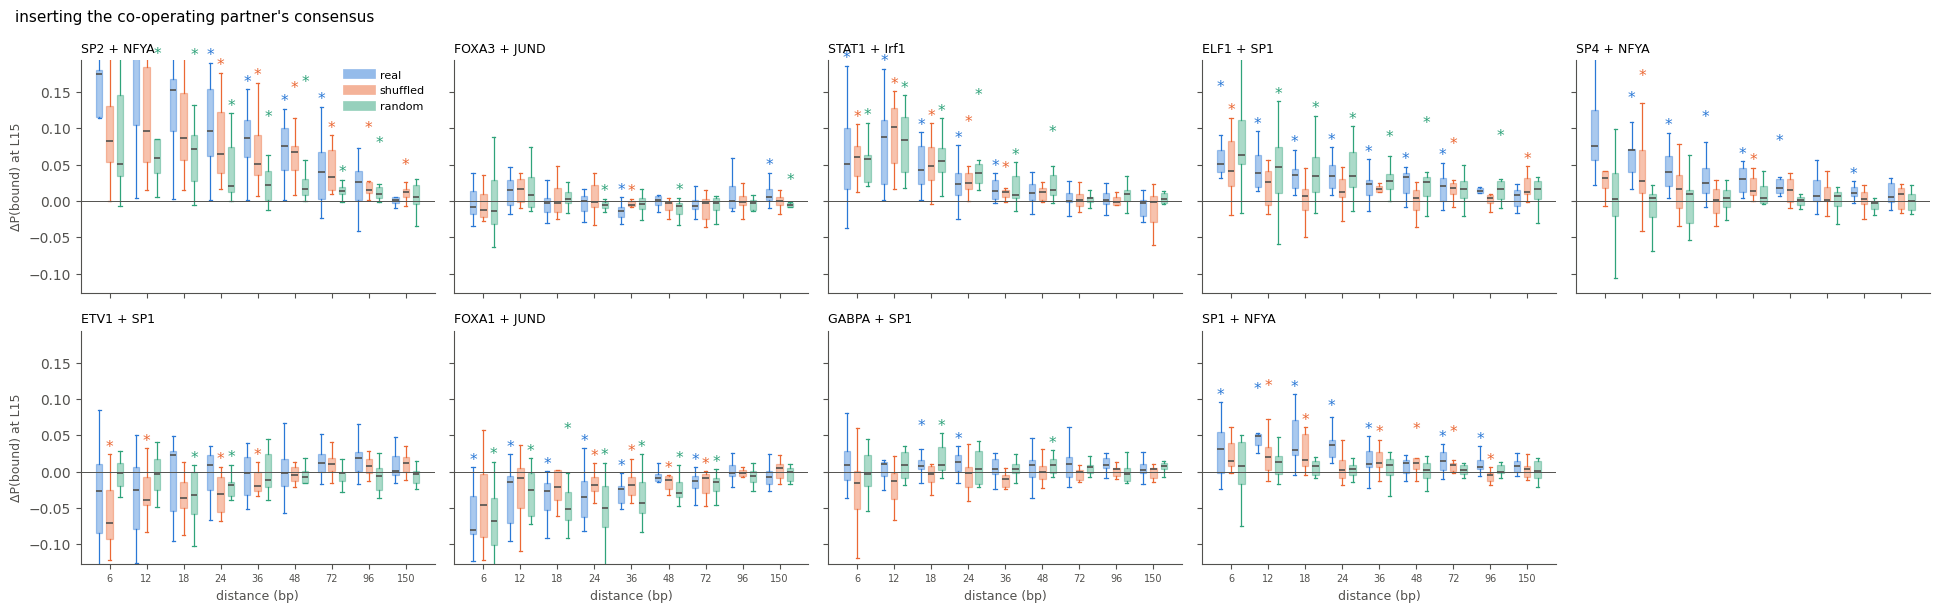

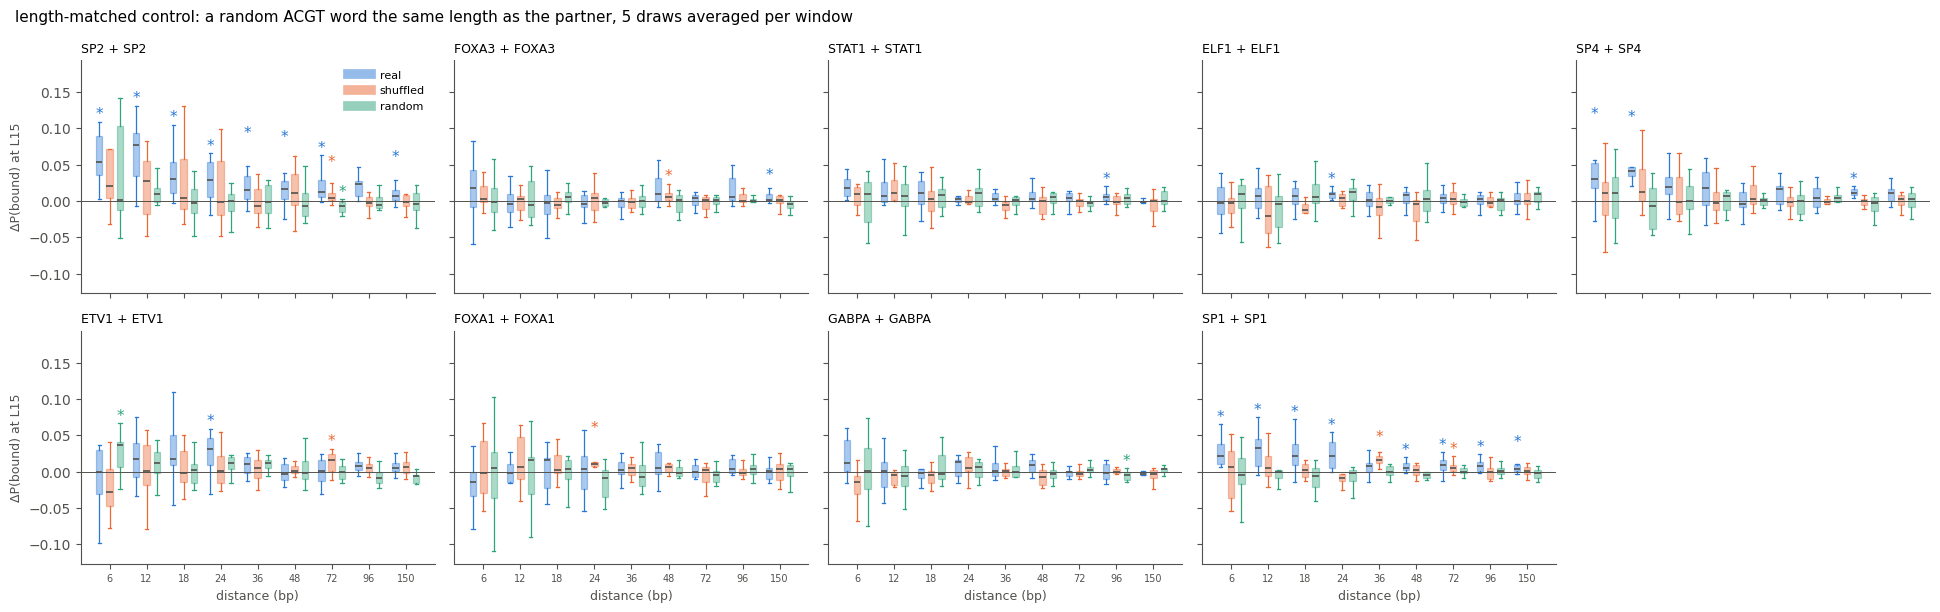

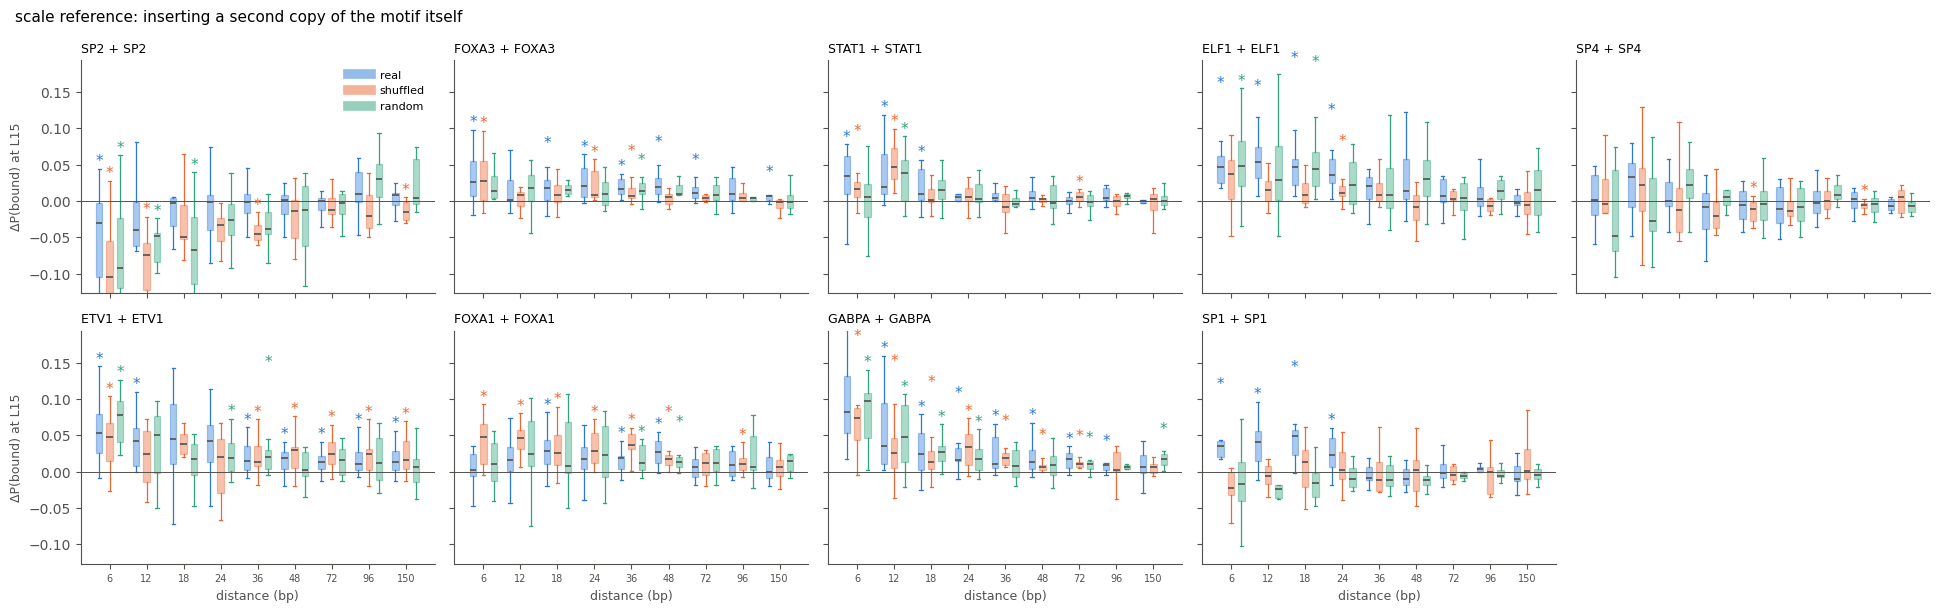

In [4]:
DS = SC["dists"]
off = np.linspace(-.28, .28, len(BGS))
nm = len(MOTIFS); ncol = min(5, nm); nrow = int(np.ceil(nm / ncol))


def panel_grid(role, fname, title):
    fig, AX = plt.subplots(nrow, ncol, figsize=(3.9 * ncol, 3.1 * nrow), squeeze=False, sharey=True, sharex=True)
    ax = AX.ravel()
    for a, m in zip(ax, MOTIFS):
        for j, bg in enumerate(BGS):
            g = W[(W.motif == m) & (W.role == role) & (W.bg == bg)]
            dat = [g[g.d == d].dP.values for d in DS]
            keep = [k for k, v in enumerate(dat) if len(v)]
            if not keep:
                continue
            pos = np.arange(len(DS)) + off[j]
            a.boxplot([dat[k] for k in keep], positions=pos[keep],
                      widths=.62 * (off[1] - off[0]) if len(BGS) > 1 else .5, patch_artist=True, showfliers=False,
                      medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=BG_C[bg], lw=.9),
                      capprops=dict(color=BG_C[bg], lw=.9),
                      boxprops=dict(facecolor=BG_C[bg], alpha=.40, edgecolor=BG_C[bg], lw=.9))
            for k in keep:
                q = T[(T.motif == m) & (T.role == role) & (T.background == bg) & (T.d == DS[k])]["p"]
                if len(q) and q.iloc[0] < .05:
                    a.annotate("*", (pos[k], np.max(dat[k])), fontsize=11, color=BG_C[bg], ha="center", va="bottom")
        a.axhline(0, c=INK, lw=.7)
        a.set_xticks(np.arange(len(DS))); a.set_xticklabels(DS, fontsize=7)
        lab = MJ[m]["partner"] if role == "partner" else m
        a.set_title(f"{m} + {lab}" if role == "partner" else f"{m} + {m}", loc="left", fontsize=9)
    for a in AX[:, 0]:
        a.set_ylabel(f"ΔP(bound) at L{LP}", fontsize=9)
    for a in AX[-1, :]:
        a.set_xlabel("distance (bp)", fontsize=9)
    for a in ax[nm:]:
        a.axis("off")
    ax[0].set_ylim(W.dP.quantile(.003), W.dP.quantile(.997))
    ax[0].legend(handles=[plt.Line2D([], [], color=BG_C[b], lw=7, alpha=.5, label=b) for b in BGS],
                 frameon=False, fontsize=8)
    fig.suptitle(title, x=.01, ha="left", fontsize=11)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=150, bbox_inches="tight"); plt.show()


panel_grid("partner", "box_partner.png", "inserting the co-operating partner's consensus")
if (W.role == "randseq").any():
    panel_grid("randseq", "box_randseq.png",
               f"length-matched control: a random ACGT word the same length as the partner, "
               f"{SC.get('n_rand', 0)} draws averaged per window")
if SC["include_self"]:
    panel_grid("self", "box_self.png", "scale reference: inserting a second copy of the motif itself")


## 3.2 End


In [5]:
from google.colab import runtime
runtime.unassign()
